# 🎬 Netflix Content Data Analysis

An exploratory data analysis (EDA) of the Netflix titles dataset — looking at what kind of content is on the platform, how the catalog has grown over time, and where it comes from.

**Dataset:** Netflix Movies and TV Shows (`netflix_titles.csv`) — includes title, type, director, cast, country, date added, release year, rating, duration, and genres.

**Goal:** Answer a set of business-style questions about Netflix's content library using pandas for analysis and seaborn/matplotlib for visualization.

## Contents
1. Setup & Data Cleaning
2. Movies vs TV Shows
3. Release Year Trend
4. Content Rating Distribution
5. Top 10 Countries
6. Top 10 Genres
7. Top 10 Directors
8. Movie Duration Distribution
9. Titles Added by Year
10. Key Findings


## 📂 Dataset Information

The dataset contains information about Netflix movies and TV shows, including:

- Content type (Movie/TV Show)
- Title
- Director
- Cast
- Country
- Date added to Netflix
- Release year
- Rating
- Duration
- Genre categories


## 🛠️ Technologies Used

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
sns.set_theme(style="whitegrid")


# Local/GitHub setup: keep netflix_titles.csv in the same folder as this notebook
df = pd.read_csv("netflix_titles.csv")


In [4]:
import os

# Folder where all chart PNGs get saved (created once, reused by every plt.savefig() call below)
os.makedirs("images", exist_ok=True)


## 🧹 Data Cleaning

Before analysis, we check the shape of the data, look for missing values and duplicates,
and drop rows that are missing key fields (`date_added`, `rating`, `duration`) since those
are needed for several of the analyses below.


In [5]:
df.head()


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [6]:
df.shape  # (rows, columns)


(8807, 12)

In [7]:
df.columns


Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='str')

In [8]:
df.info()  # column dtypes + non-null counts


<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 825.8 KB


In [9]:
df.describe()  # summary stats for numeric columns (mainly release_year here)


,release_year
count,8807.000000
mean,2014.180198
std,8.819312
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2019.000000
max,2021.000000


In [10]:
df.isnull().sum()  # missing values per column


show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

In [11]:
df.duplicated().sum()  # count of fully duplicate rows


np.int64(0)

In [12]:
df.isnull().sum() / len(df) * 100  # missing values as a percentage of total rows


show_id          0.000000
type             0.000000
title            0.000000
director        29.908028
cast             9.367549
country          9.435676
date_added       0.113546
release_year     0.000000
rating           0.045418
duration         0.034064
listed_in        0.000000
description      0.000000
dtype: float64

In [13]:
# Drop rows missing date_added, rating, or duration — these columns are required
# for the "titles added by year", "content rating", and "movie duration" analyses.
# subset=[...] limits the check to just these columns instead of dropping on ANY missing value.
df = df.dropna(subset=["date_added", "rating", "duration"])


In [14]:
df.shape  # confirm how many rows were dropped


(8790, 12)

In [15]:
df.isnull().sum()  # confirm the target columns are now clean


show_id            0
type               0
title              0
director        2621
cast             825
country          829
date_added         0
release_year       0
rating             0
duration           0
listed_in          0
description        0
dtype: int64

## 📊 Analysis 1: Movies vs TV Shows

**Business Question:** How many Movies and TV Shows are available on Netflix?


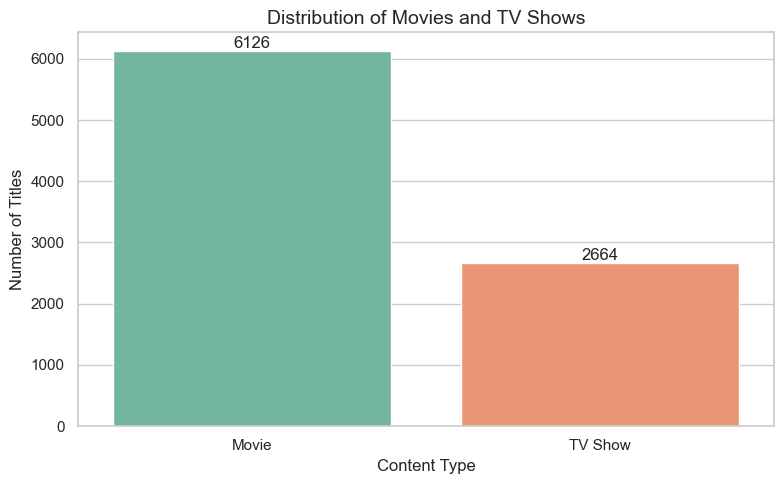

In [16]:

import matplotlib.pyplot as plt
import seaborn as sns
import os

# Count the number of Movies and TV Shows
content_counts = df["type"].value_counts()

# Create images folder if it does not exist
os.makedirs("images", exist_ok=True)

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="type",
    hue="type",
    palette="Set2",
    legend=False
)

# Display count labels above the bars
for container in ax.containers:
    ax.bar_label(container)

plt.title("Distribution of Movies and TV Shows", fontsize=14)
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")

plt.tight_layout()

# Save the chart
plt.savefig(
    "images/movies_vs_tvshows.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Observation

Netflix contains significantly more Movies than TV Shows. Movies represent the majority of the content available on the platform.


## 📊 Analysis 2: Release Year Analysis

**Business Question:** How has the number of Netflix titles changed over the years?


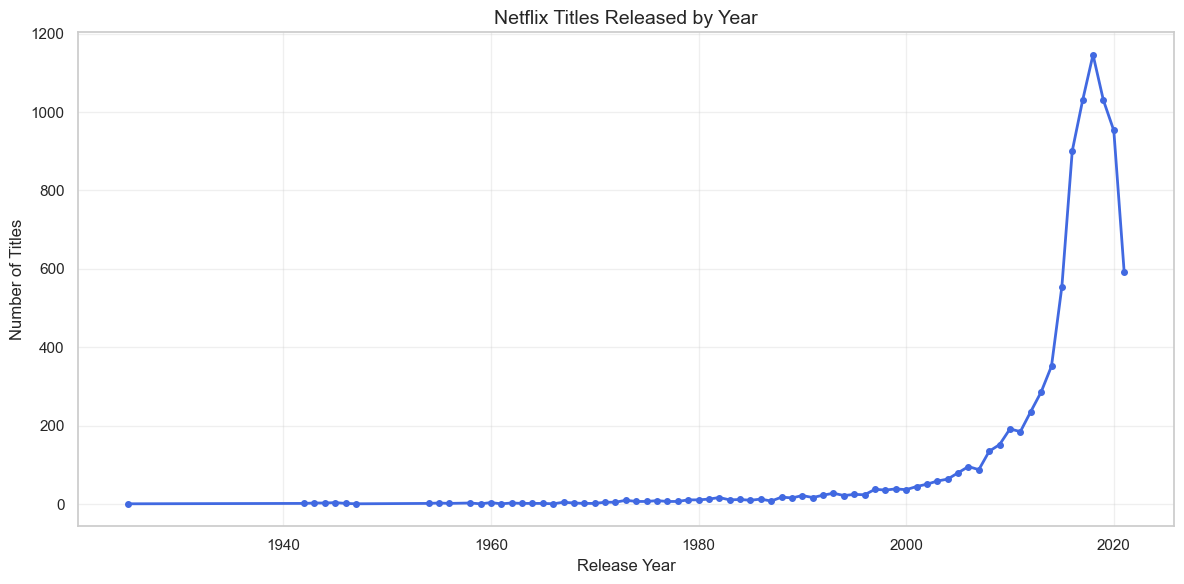

In [17]:
# Count the number of titles released each year
release_counts = df["release_year"].value_counts().sort_index()  # sort_index() so the line plot reads left-to-right by year

plt.figure(figsize=(12,6))

plt.plot(
    release_counts.index,
    release_counts.values,
    color="royalblue",
    linewidth=2,
    marker="o",
    markersize=4
)

plt.title("Netflix Titles Released by Year", fontsize=14)

plt.xlabel("Release Year")

plt.ylabel("Number of Titles")

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "images/release_year_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Observation

The number of Netflix titles released remained relatively low before 2000. The number of releases increased rapidly after 2015, showing a significant growth in available content.


## 📊 Analysis 3: Content Rating Analysis

**Business Question:** What are the most common content ratings on Netflix?


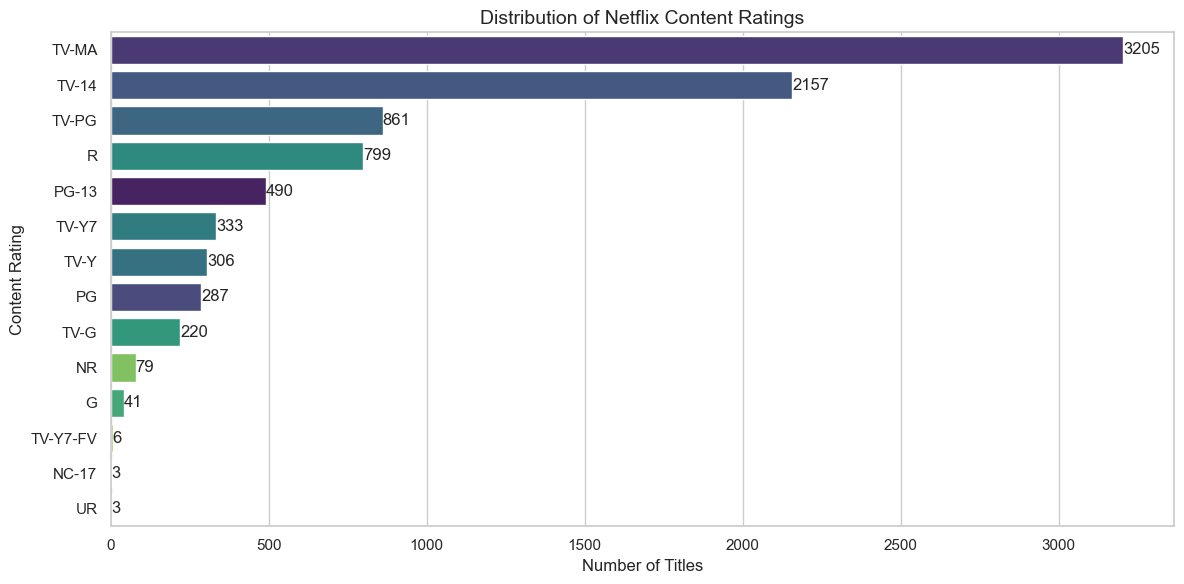

In [18]:
# Count the number of titles in each content rating
rating_counts = df["rating"].value_counts()

plt.figure(figsize=(12,6))

ax = sns.countplot(
    data=df,
    y="rating",
    order=rating_counts.index,  # order bars from most to least common, matching rating_counts
    hue="rating",
    palette="viridis",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Distribution of Netflix Content Ratings", fontsize=14)

plt.xlabel("Number of Titles")
plt.ylabel("Content Rating")

plt.tight_layout()

plt.savefig(
    "images/content_rating_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Observation

TV-MA is the most common content rating on Netflix, followed by TV-14. Family-oriented ratings such as G and TV-Y are comparatively less common.


## 📊 Analysis 4: Top 10 Countries

**Business Question:** Which countries have contributed the highest number of titles to Netflix?


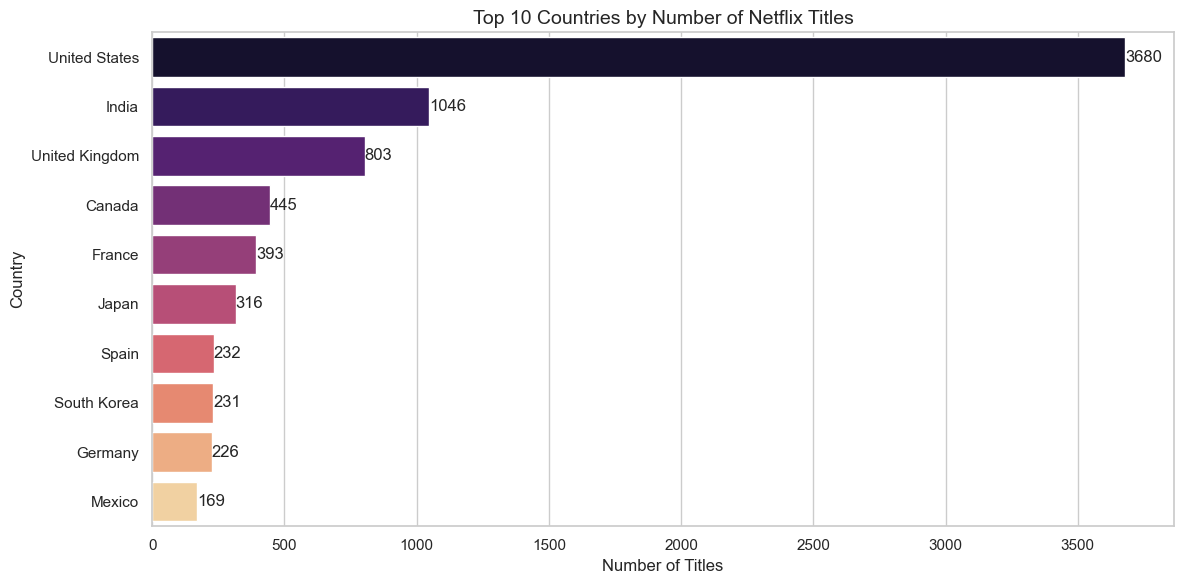

In [19]:
# Count titles by country
# Some rows list multiple countries as "Country A, Country B" — split() breaks that into a list,
# and explode() turns each list item into its own row so every country gets counted individually.
country_counts = (
    df["country"]
    .dropna()
    .str.split(", ")
    .explode()
    .value_counts()
    .head(10)
)

plt.figure(figsize=(12,6))

ax = sns.barplot(
    x=country_counts.values,
    y=country_counts.index,
    hue=country_counts.index,
    palette="magma",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Top 10 Countries by Number of Netflix Titles", fontsize=14)

plt.xlabel("Number of Titles")
plt.ylabel("Country")

plt.tight_layout()

plt.savefig(
    "images/top_countries.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Observation

The United States has the highest number of Netflix titles, followed by India and the United Kingdom. These countries contribute a significant portion of the platform's content library.


## 📊 Analysis 5: Top 10 Genres

**Business Question:** Which genres are the most common on Netflix?


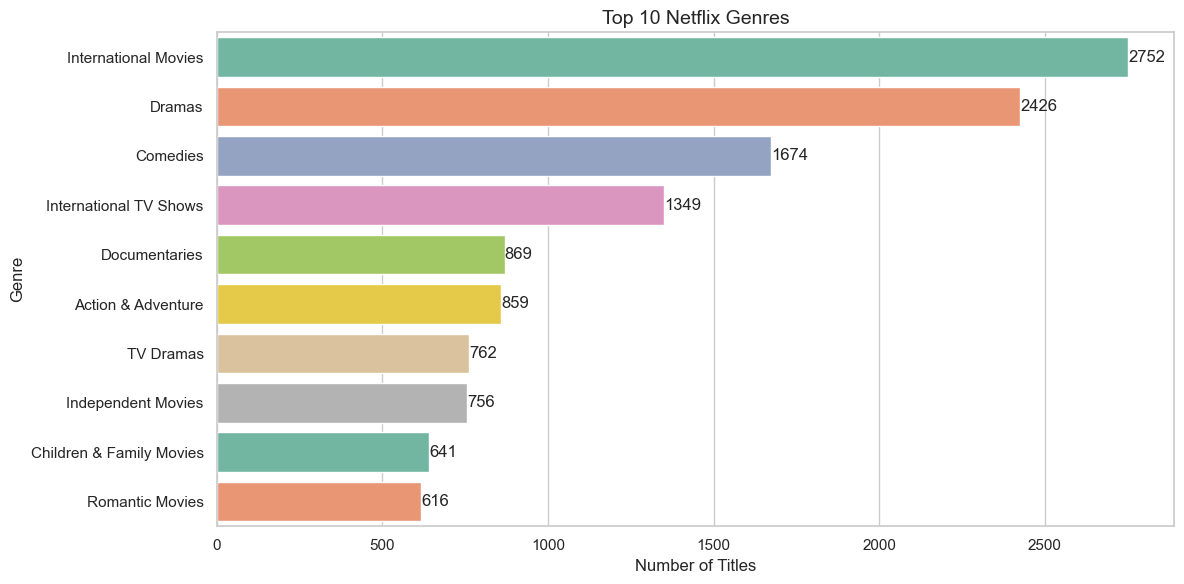

In [20]:
# Split multiple genres (e.g. "Dramas, International Movies") into separate rows, same explode() trick as Analysis 4
genres = (
    df["listed_in"]
    .str.split(", ")
    .explode()
)

# Count the top 10 genres
genre_counts = genres.value_counts().head(10)

plt.figure(figsize=(12,6))

ax = sns.barplot(
    x=genre_counts.values,
    y=genre_counts.index,
    hue=genre_counts.index,
    palette="Set2",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Top 10 Netflix Genres", fontsize=14)

plt.xlabel("Number of Titles")
plt.ylabel("Genre")

plt.tight_layout()

plt.savefig(
    "images/top_genres.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Observation

Drama is one of the most common genres on Netflix, followed by International Movies and Comedy. These genres dominate the platform's content library.


## 📊 Analysis 6: Top 10 Directors

**Business Question:** Who are the top 10 directors with the highest number of titles on Netflix?


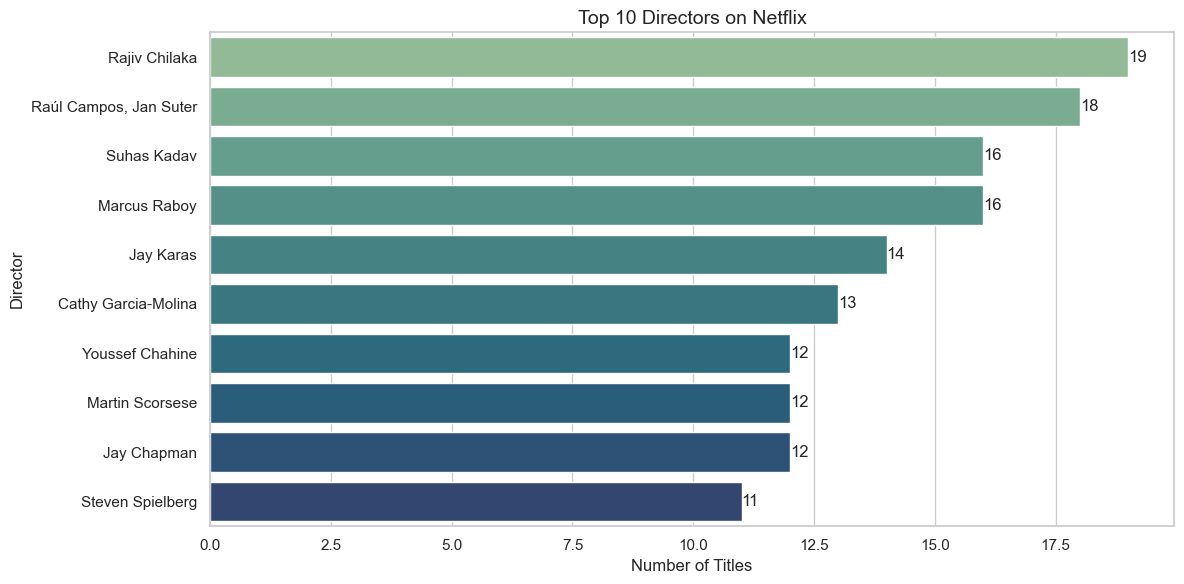

In [21]:
# Count the top 10 directors
director_counts = (
    df["director"]
    .dropna()
    .value_counts()
    .head(10)
)

plt.figure(figsize=(12,6))

ax = sns.barplot(
    x=director_counts.values,
    y=director_counts.index,
    hue=director_counts.index,
    palette="crest",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Top 10 Directors on Netflix", fontsize=14)

plt.xlabel("Number of Titles")
plt.ylabel("Director")

plt.tight_layout()

plt.savefig(
    "images/top_directors.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Observation

Rajiv Chilaka has directed the highest number of titles available on Netflix among all directors in the dataset.


## 📊 Analysis 7: Movie Duration Distribution

**Business Question:** What is the distribution of movie durations on Netflix?


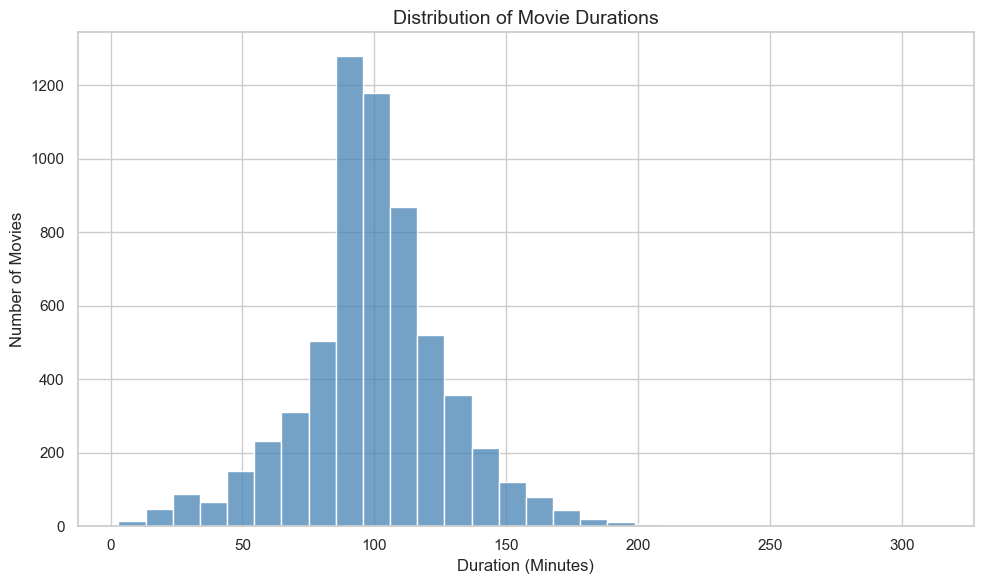

In [22]:
# Select only movies (TV Shows use "duration" for number of seasons, not minutes, so they're excluded here)
movies = df[df["type"] == "Movie"].copy()

# duration is stored as text like "90 min" — strip " min" and convert to an integer for plotting
movies["duration_minutes"] = movies["duration"].str.replace(" min", "").astype(int)

plt.figure(figsize=(10,6))

sns.histplot(
    data=movies,
    x="duration_minutes",
    bins=30,
    color="steelblue"
)

plt.title("Distribution of Movie Durations", fontsize=14)

plt.xlabel("Duration (Minutes)")
plt.ylabel("Number of Movies")

plt.tight_layout()

plt.savefig(
    "images/movie_duration_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Observation

Most Netflix movies have a duration between approximately 80 and 120 minutes.


## 📊 Analysis 8: Titles Added to Netflix by Year

**Business Question:** How has the number of titles added to Netflix changed over the years?


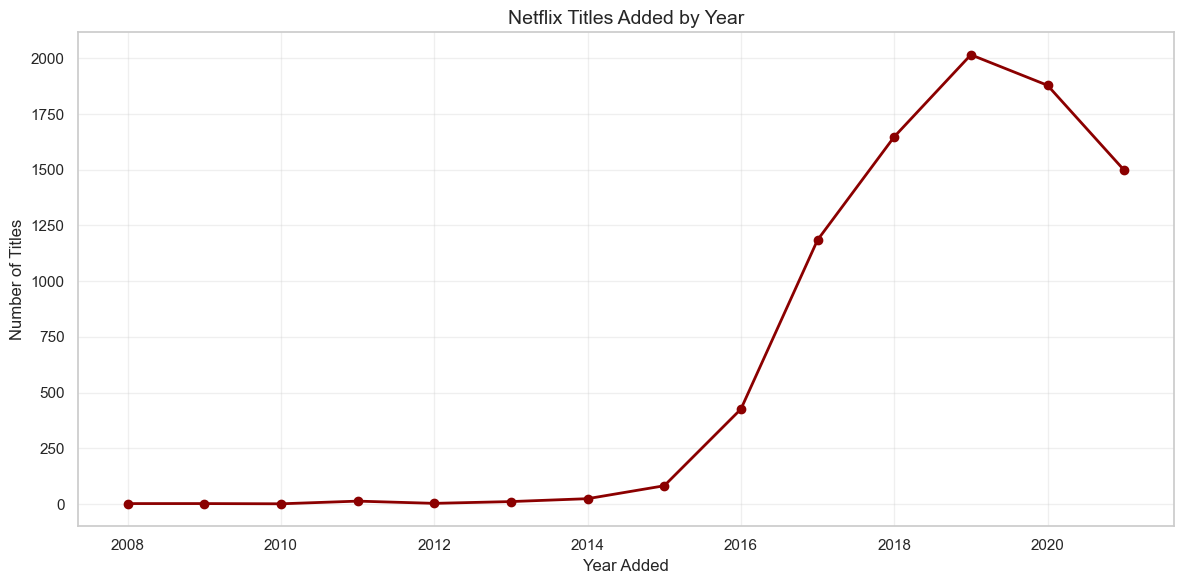

In [23]:
# Convert date_added column into datetime format
# format="mixed" handles the fact that dates in this column aren't all written the same way (e.g. extra whitespace, varying formats)
# errors="coerce" turns any date pandas can't parse into NaT instead of crashing
df["date_added"] = pd.to_datetime(
    df["date_added"],
    format="mixed",
    errors="coerce"
)

# Extract the year
df["added_year"] = df["date_added"].dt.year

# Count titles added each year
added_counts = df["added_year"].value_counts().sort_index()

plt.figure(figsize=(12,6))

plt.plot(
    added_counts.index,
    added_counts.values,
    color="darkred",
    marker="o",
    linewidth=2
)

plt.title("Netflix Titles Added by Year", fontsize=14)
plt.xlabel("Year Added")
plt.ylabel("Number of Titles")

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "images/titles_added_by_year.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Observation

Netflix added a large number of titles between 2016 and 2020, showing aggressive content expansion during this period.


## ✅ Key Findings

- Netflix has more Movies than TV Shows in its content library.
- The number of Netflix titles increased significantly after 2015, showing rapid platform growth.
- TV-MA is the most common content rating, indicating a large focus on mature audiences.
- The United States contributes the highest number of titles on Netflix.
- Drama is among the most common genres available on the platform.
- Most Netflix movies have a duration between 80 and 120 minutes.
- Netflix added a large number of titles between 2016 and 2020, showing aggressive content expansion during this period.


In [24]:
import shutil

# Bundle every saved chart into a single zip for easy download/sharing
shutil.make_archive("netflix_graphs", "zip", "images")

# --- Uncomment below if running in Google Colab to trigger a browser download ---
# from google.colab import files
# files.download("netflix_graphs.zip")


'c:\\Users\\nandi\\Downloads\\Netflix-Data-Analysis-main\\Netflix-Data-Analysis-main\\netflix_graphs.zip'